# Phishing Website Detection Using Machine Learning
**Course:** Information Security Lab | **Group 9**
**Members:** Tanseer Haider, Hassan Ameer Ahmad, M. Arham

## Module 1: Project Setup and Dataset Understanding
**Goal:** Load the public UCI Phishing Websites dataset and understand it before training any model.

**Why this module?** A model is only as good as its data. We must know what the data is, what each feature means, and whether it has problems.

## Step 1: Install and import libraries

In [1]:
!pip install ucimlrepo -q

import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

print("Libraries ready")

Libraries ready


## Step 2: Load the dataset (UCI Phishing Websites, ID 327)

In [2]:
data = fetch_ucirepo(id=327)

X = data.data.features   # the 30 features
y = data.data.targets    # the label (phishing or legitimate)

print("Dataset loaded from UCI")

Dataset loaded from UCI


## Step 3: Look at the data

In [3]:
print("Features (X) shape:", X.shape)
print("Label (y) shape:", y.shape)
print("Number of websites :", X.shape[0])
print("Number of features :", X.shape[1])

Features (X) shape: (11055, 30)
Label (y) shape: (11055, 1)
Number of websites : 11055
Number of features : 30


In [4]:
# First 5 rows
X.head()

,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1


In [5]:
# Column names
print(list(X.columns))

['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url', 'redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe', 'age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report']


In [6]:
# Data types
X.dtypes

,0
having_ip_address,int64
url_length,int64
shortining_service,int64
having_at_symbol,int64
double_slash_redirecting,int64
prefix_suffix,int64
having_sub_domain,int64
sslfinal_state,int64
domain_registration_length,int64
favicon,int64


## Step 4: Check data quality

In [7]:
# 1) Missing values
print("Total missing values in features:", X.isnull().sum().sum())
print("Total missing values in label   :", y.isnull().sum().sum())

Total missing values in features: 0
Total missing values in label   : 0


In [8]:
# 2) Duplicate rows (same website pattern repeated)
full = pd.concat([X, y], axis=1)
dups = full.duplicated().sum()
print("Duplicate rows:", dups)
print("Percentage    : {:.1f}%".format(dups / len(full) * 100))

Duplicate rows: 5206
Percentage    : 47.1%


result
 1    6157
-1    4898
Name: count, dtype: int64

result
 1    55.7
-1    44.3
Name: count, dtype: float64


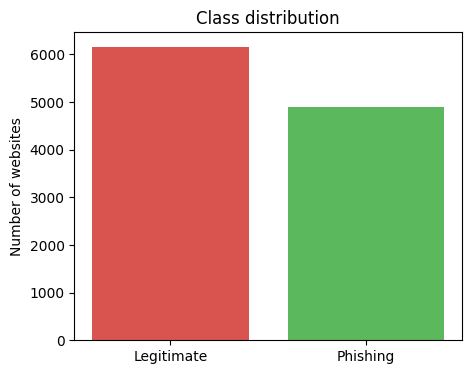

In [9]:
# 3) Class balance: how many phishing vs legitimate?
label_col = y.columns[0]
counts = y[label_col].value_counts()
print(counts)
print()
print((counts / counts.sum() * 100).round(1))

names = {-1: "Phishing", 1: "Legitimate"}
plt.figure(figsize=(5, 4))
plt.bar([names.get(i, str(i)) for i in counts.index], counts.values, color=["#d9534f", "#5cb85c"][:len(counts)])
plt.title("Class distribution")
plt.ylabel("Number of websites")
plt.show()

## Step 5: Understand the features

The 30 features are grouped into 4 groups:

| Group | What it looks at | Examples |
|---|---|---|
| Address bar based | The URL itself | having_IP_Address, URL_Length, having_At_Symbol |
| Domain based | Age and reputation of the domain | age_of_domain, DNSRecord, web_traffic |
| HTML / JavaScript based | The page code | Iframe, RightClick, popUpWidnow |
| Abnormal based | Strange behaviour of the page | Request_URL, URL_of_Anchor, SFH |

**What do the values mean?**
- **-1** = phishing-like (suspicious sign)
- **0** = suspicious (in between)
- **1** = legitimate-like (safe sign)

**The label:** `-1` = Phishing website, `1` = Legitimate website.

In [10]:
groups = {
    "Address bar based": ["having_IP_Address", "URL_Length", "Shortining_Service", "having_At_Symbol",
        "double_slash_redirecting", "Prefix_Suffix", "having_Sub_Domain", "SSLfinal_State",
        "Domain_registeration_length", "Favicon", "port", "HTTPS_token"],
    "Domain based": ["age_of_domain", "DNSRecord", "web_traffic", "Page_Rank", "Google_Index",
        "Links_pointing_to_page", "Statistical_report"],
    "HTML / JavaScript based": ["Redirect", "on_mouseover", "RightClick", "popUpWidnow", "Iframe"],
    "Abnormal based": ["Request_URL", "URL_of_Anchor", "Links_in_tags", "SFH",
        "Submitting_to_email", "Abnormal_URL"],
}

for g, cols in groups.items():
    present = [c for c in cols if c in X.columns]
    print(f"{g} ({len(present)} features):")
    print("   ", present)
    print()

Address bar based (2 features):
    ['double_slash_redirecting', 'port']

Domain based (2 features):
    ['age_of_domain', 'web_traffic']

HTML / JavaScript based (1 features):
    ['on_mouseover']

Abnormal based (0 features):
    []



In [11]:
# What values does each feature take? (-1, 0, 1)
for col in X.columns:
    print(f"{col:30s} -> {sorted(X[col].unique())}")

having_ip_address              -> [np.int64(-1), np.int64(1)]
url_length                     -> [np.int64(-1), np.int64(0), np.int64(1)]
shortining_service             -> [np.int64(-1), np.int64(1)]
having_at_symbol               -> [np.int64(-1), np.int64(1)]
double_slash_redirecting       -> [np.int64(-1), np.int64(1)]
prefix_suffix                  -> [np.int64(-1), np.int64(1)]
having_sub_domain              -> [np.int64(-1), np.int64(0), np.int64(1)]
sslfinal_state                 -> [np.int64(-1), np.int64(0), np.int64(1)]
domain_registration_length     -> [np.int64(-1), np.int64(1)]
favicon                        -> [np.int64(-1), np.int64(1)]
port                           -> [np.int64(-1), np.int64(1)]
https_token                    -> [np.int64(-1), np.int64(1)]
request_url                    -> [np.int64(-1), np.int64(1)]
url_of_anchor                  -> [np.int64(-1), np.int64(0), np.int64(1)]
links_in_tags                  -> [np.int64(-1), np.int64(0), np.int64(1)]
sfh  

## Step 6: Module 1 summary

In [12]:
print("=== MODULE 1 SUMMARY ===")
print("Dataset            : UCI Phishing Websites (ID 327), public, CC BY 4.0")
print("Websites           :", X.shape[0])
print("Features           :", X.shape[1])
print("Missing values     :", X.isnull().sum().sum())
print("Duplicate rows     :", dups)
print("Phishing / Legit   :", counts.get(-1, 0), "/", counts.get(1, 0))
print("Next (Module 2)    : remove duplicates + EDA charts")

=== MODULE 1 SUMMARY ===
Dataset            : UCI Phishing Websites (ID 327), public, CC BY 4.0
Websites           : 11055
Features           : 30
Missing values     : 0
Duplicate rows     : 5206
Phishing / Legit   : 4898 / 6157
Next (Module 2)    : remove duplicates + EDA charts
